# The population balance against the particle-replacement walk of discrete-element crusher models

**Question:** Does the replacement rule that discrete-element crusher models use, run with the product's own selection and breakage, reproduce the Whiten product, and how many sampled parcels does it need to do so within one percent of the mass?

- **Level:** 3, State of the art
- **Prerequisites:** notebook 02 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say what the discrete-element state of the art for crushers does, in its two families, and what the population balance approximates of it;
- run a replacement walk, the stochastic rule at the core of the particle-replacement family, with the product's own selection and breakage;
- compare the walk's product with the Whiten balance, and measure the sampling error as the number of parcels grows;
- state plainly what the walk reproduces of the literature and what it cannot.

## Setup

Numpy and matplotlib. The random draws come from numpy's generator with a fixed seed, so every run gives the same numbers.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the pieces of notebook 02: the selection, the breakage matrix and the engine's Whiten solver, which is the reference the walk is compared with.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import Operating, evaluate, grid_edges, grid_mid
from pipeline.model.crusher.breakage import specific_energy, t10_of, phi_from_t10, breakage_matrix
from pipeline.model.crusher.classification import classification_params, classify
from pipeline.model.crusher.machines import REF_THROW_MM
from pipeline.model.crusher.whiten import whiten_solve
from pipeline.model.crusher.linalg import solve_lu
from pipeline.model.crusher.sieve import to_psd, size_at_passing
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The reference case S01. No discrete-element data is committed to this repository, so the literature below is cited and not run. Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads S01 and runs the engine once to get the feed distribution on the grid.

In [2]:
# Read S01, run the engine once for its feed, and fix the grid
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
result = evaluate(op)
edges, mids = grid_edges(), grid_mid()
K = len(mids)
feed = np.array(result.feed.mass)

print("classes:", K, "| feed mass:", feed.sum().round(12), "| engine P80:", round(result.p80, 3), "mm")

classes: 28 | feed mass: 1.0 | engine P80: 27.698 mm


## Method

**Assembling the model.** The comparison needs the selection vector $c$, the breakage matrix $B$ and the Whiten product for any setting and ore, so the cell below packs the construction of notebook 02 into one function: the classification at each class mid-size, the breakage matrix from the t10 of the ore, and the engine's own Whiten solver for the product. It then builds them for S01.

In [3]:
# Define the assembly of c, B and the Whiten product, and build them for S01
def assemble(css_mm, ore_axb):
    phi = phi_from_t10(t10_of(specific_energy(op.speed_rpm, REF_THROW_MM[op.machine]), ore_axb))
    params = classification_params(op.machine, css_mm, f80_mm=result.f80, calibrated=False, throw_mm=op.throw_mm)
    c = np.array([classify(d, params) for d in mids])
    B = np.array(breakage_matrix(edges, mids, phi)).reshape(K, K)
    return c, B, np.array(whiten_solve(c.tolist(), B.ravel().tolist(), feed.tolist(), K).product)


c, B, reference = assemble(op.css_mm, op.ore_axb)
k = classification_params(op.machine, op.css_mm, f80_mm=result.f80, calibrated=False, throw_mm=op.throw_mm)
print("selection range, K1 and K2 of S01 [mm]:", round(k.k1, 2), round(k.k2, 2))

selection range, K1 and K2 of S01 [mm]: 29.0 68.4


**The method being compared.** The product's crusher model is the population balance of notebook 02: a deterministic linear system in which the selection $C$ and the breakage $B$ summarise what happens in the chamber, and the product is $p = (I - C)(I - BC)^{-1} f$ (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf; Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193). It needs no geometry and runs in milliseconds. The cell prints the reference product's P80 and the share of the mass above the 20 mm class edge, the two numbers the walk must reproduce.

In [4]:
# Reference product: P80 and the share of mass above the 20 mm class edge
coarse = [i for i in range(K) if edges[i + 1] >= 19.9]
balance_p80 = size_at_passing(to_psd(edges, reference.tolist()), 0.8)
print("P80 [mm]:", round(balance_p80, 3), "| mass above the 20 mm edge:", round(float(reference[coarse].sum()), 4))

P80 [mm]: 27.698 | mass above the 20 mm edge: 0.2965


## State of the art

**The discrete-element family.** The state of the art for the mechanism of a crusher is the discrete element method, which resolves the particles, their contacts and their breakage in the chamber's geometry. Two families are in the sources the product cites. In **particle replacement**, a particle that meets a breakage criterion is deleted and replaced by a set of smaller fragments sized from a breakage-function distribution; Cleary and Sinnott (2015; https://doi.org/10.1016/j.mineng.2014.10.021) develop it for compression crushers. In the **bonded-particle** family the rock is an assembly of sub-particles and the fracture emerges from the bond model; Quist and Evertsson (2016; https://doi.org/10.1016/j.mineng.2015.11.004) calibrate it to single-particle breakage for a cone crusher. Both are offline tools: an industrial step takes hours of computation, which is why the population balance is the fast approximation the studio runs live.

What can be run here, and what cannot, has to be said exactly. Neither family's code or data is in this repository, so their numbers are not reproduced. What the two share with the balance is a stochastic reading of the same two functions: a particle that is selected is replaced by fragments drawn from the appearance distribution, and a fragment that is still selected is broken again. That rule can be run on the product's own $C$ and $B$, with each unit of mass as a parcel so that the walk stays linear in mass. If it reproduced the balance, the balance would be the exact expectation of the replacement rule; the question is whether it does.

**The replacement walk.** The cell draws the feed parcels from the feed distribution, then repeats a single rule until no parcel is left in the chamber: each parcel of class $j$ is nipped with probability $c_j$, and a nipped parcel is replaced by a parcel of class $i$ drawn with probability $B_{ij}$; a parcel that is not nipped leaves and is counted in the product. The loop works on counts of parcels per class, so each pass is a binomial draw per class and a multinomial draw per nipped class, and it ends because every replacement lands strictly on a finer class. The function returns the product as a distribution.

In [5]:
# The replacement walk on counts of parcels per class, seeded; it returns the product distribution
def replacement_walk(parcels, seed, c, B):
    rng = np.random.default_rng(seed)
    inside = rng.multinomial(parcels, feed)
    product = np.zeros(K, dtype=np.int64)
    nips = 0
    while inside.sum() > 0:
        nipped = rng.binomial(inside, c)
        product += inside - nipped
        nips += nipped.sum()
        inside = np.zeros(K, dtype=np.int64)
        for j in np.nonzero(nipped)[0]:
            inside += rng.multinomial(nipped[j], B[:, j])
    return product / product.sum(), nips / parcels


walk, nips_per_parcel = replacement_walk(200_000, 42, c, B)
print("largest class-mass difference to the Whiten product:", np.abs(walk - reference).max().round(5))
print("total variation distance:", (0.5 * np.abs(walk - reference).sum()).round(5))

largest class-mass difference to the Whiten product: 0.00168
total variation distance: 0.00372


The walk with 200 000 parcels lands within 0.17 percentage points of the balance in every class. The figure lays the two products over each other class by class. Both are zero in the coarse classes that are always nipped, and both put the bulk of their mass between 5 and 40 mm.

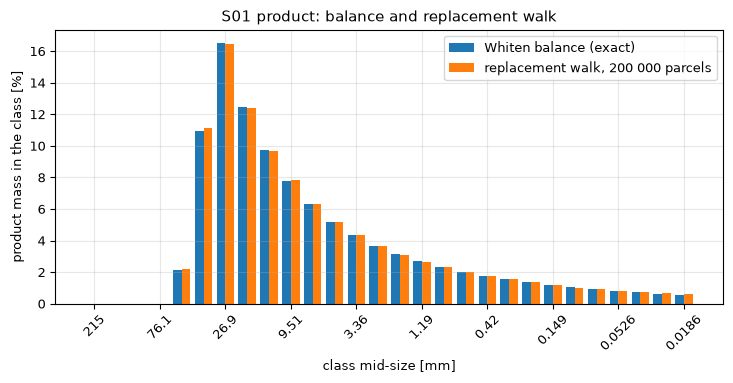

In [6]:
# Bar chart of the Whiten product and the replacement-walk product per class
position = np.arange(K)
fig, ax = plt.subplots()
ax.bar(position - 0.2, reference * 100, 0.4, label="Whiten balance (exact)")
ax.bar(position + 0.2, walk * 100, 0.4, label="replacement walk, 200 000 parcels")
ax.set_xticks(position[::3], [f"{m:.3g}" for m in mids[::3]], rotation=45)
ax.set_xlabel("class mid-size [mm]")
ax.set_ylabel("product mass in the class [%]")
ax.set_title("S01 product: balance and replacement walk")
ax.legend()
fig.tight_layout()
plt.show()

**A second observable, the recirculation.** The product is one output of the walk; the number of nip events is another, and the balance predicts it as well: it is the sum of $c_j x_j$ over classes, the quantity that notebook 02 read as 0.8858 nips per unit of feed. The cell solves the balance with the engine's LU routine for that sum and compares it with the number of nips per parcel that the walk counted.

In [7]:
# Nip events per unit of feed from the balance (engine's LU solve) against the walk's own count
x = np.array(solve_lu((np.eye(K) - B * c[None, :]).ravel().tolist(), feed.tolist(), K))
print("balance, sum of c x:", round(float((c * x).sum()), 4), "| walk, nips per parcel:", round(float(nips_per_parcel), 4))

balance, sum of c x: 0.8858 | walk, nips per parcel: 0.8843


The bars agree to the eye in every class, which says that the walk and the balance are the same model seen two ways: the balance is the expectation of the walk, and the walk is a sampling of the balance. The picture cannot show the quality of the agreement, since a 0.17-point difference is below the resolution of the bars. The next cell measures it, as a function of the number of parcels, with five independent seeds per size, and the figure after it reads the slope.

In [8]:
# Total-variation distance of the walk to the Whiten product against the number of parcels, five seeds each
sizes = [10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]
distance = {n_parcels: [0.5 * np.abs(replacement_walk(n_parcels, seed, c, B)[0] - reference).sum() for seed in range(5)] for n_parcels in sizes}
for n_parcels, values in distance.items():
    print(f"{n_parcels:>9,d} parcels: mean {np.mean(values):.5f}, min {np.min(values):.5f}, max {np.max(values):.5f}")

    1,000 parcels: mean 0.05660, min 0.03841, max 0.07280
   10,000 parcels: mean 0.01649, min 0.01410, max 0.01867
  100,000 parcels: mean 0.00597, min 0.00396, max 0.00719
1,000,000 parcels: mean 0.00160, min 0.00136, max 0.00193


The figure plots the mean distance on logarithmic axes against the one-over-square-root law drawn through the first point.

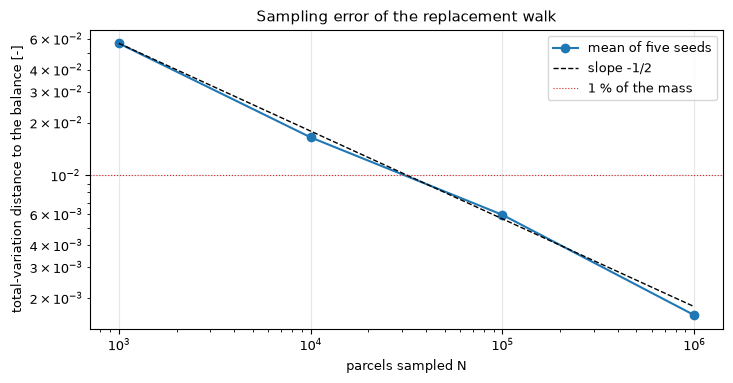

fitted slope: -0.509


In [9]:
# Plot the mean distance on logarithmic axes with the 1 / sqrt(N) law through the first point
mean_distance = np.array([np.mean(distance[s]) for s in sizes])
fig, ax = plt.subplots()
ax.loglog(sizes, mean_distance, "o-", label="mean of five seeds")
ax.loglog(sizes, mean_distance[0] * np.sqrt(sizes[0] / np.array(sizes)), "k--", lw=1, label="slope -1/2")
ax.axhline(0.01, color="tab:red", lw=0.8, ls=":", label="1 % of the mass")
ax.set_xlabel("parcels sampled N")
ax.set_ylabel("total-variation distance to the balance [-]")
ax.set_title("Sampling error of the replacement walk")
ax.legend()
fig.tight_layout()
plt.show()
slope = np.polyfit(np.log(sizes), np.log(mean_distance), 1)[0]
print("fitted slope:", round(float(slope), 3))

The measured distance falls with a slope close to $-1/2$, the law of Monte Carlo sampling, and it crosses the 1 percent line between $10^4$ and $10^5$ parcels. The walk therefore converges to the balance and does so at the standard rate; there is no bias to find at this resolution. The figure does not say that the balance is correct for a real crusher. It says that the balance is what the replacement rule gives when the rule is fed the same $C$ and $B$, so the whole difference between a particle-replacement simulation and this product lies in where $C$ and $B$ come from: the DEM derives them from contact mechanics and the chamber's geometry, the product from the published relations and a calibration.

**Does the equivalence survive other settings and ores?** One operating point could be a coincidence of the numbers. The cell repeats the comparison for three closed-side settings and three ore hardnesses, nine combinations, each with its own selection vector and breakage matrix assembled by the same function, 100 000 parcels and one seed, and prints the total-variation distance of the walk to the balance for each.

In [10]:
# Total-variation distance of the walk to the balance for three settings and three ore hardnesses
print("CSS [mm]   A*b = 30    A*b = 55    A*b = 110")
worst_distance, p80_gap = 0.0, 0.0
for css in (op.css_mm * 0.7, op.css_mm, op.css_mm * 1.3):
    row = []
    for axb in (30, 55, 110):
        cc, BB, ref = assemble(css, axb)
        product_walk = replacement_walk(100_000, 7, cc, BB)[0]
        row.append(0.5 * np.abs(product_walk - ref).sum())
        p80_gap = max(p80_gap, abs(size_at_passing(to_psd(edges, product_walk.tolist()), 0.8) / size_at_passing(to_psd(edges, ref.tolist()), 0.8) - 1))
    worst_distance = max(worst_distance, *row)
    print(f"{css:7.1f}  " + "  ".join(f"{v:10.5f}" for v in row))
print("worst of the nine:", round(worst_distance, 5), "| largest relative P80 gap:", f"{p80_gap * 100:.3f} %")

CSS [mm]   A*b = 30    A*b = 55    A*b = 110
   22.4     0.00685     0.00567     0.00523
   32.0     0.00542     0.00478     0.00351
   41.6     0.00519     0.00540     0.00482
worst of the nine: 0.00685 | largest relative P80 gap: 0.295 %


All nine distances are of the same small size, a few thousandths, so the agreement is a property of the rule and not of S01's numbers. The hardest ore with the tightest setting needs the most recirculation and gives the largest distance of the table, as it has the longest walks. The last cell translates the distance into the number a plant cares about, the product P80, read by the same interpolation as the engine's, and compares it with the engine's own value.

In [11]:
# P80 of the walk's product by the engine's interpolation, against the engine's P80
walk_p80 = [size_at_passing(to_psd(edges, replacement_walk(100_000, seed, c, B)[0].tolist()), 0.8) for seed in range(5)]
print("P80 of the walk over five seeds [mm]:", np.round(walk_p80, 3))
print("engine P80 [mm]:", round(result.p80, 3), "| largest relative difference:", f"{max(abs(v - result.p80) for v in walk_p80) / result.p80 * 100:.3f} %")

P80 of the walk over five seeds [mm]: [27.811 27.617 27.795 27.704 27.686]
engine P80 [mm]: 27.698 | largest relative difference: 0.409 %


## Results

**Answer:** yes. The replacement walk run on the product's own selection and breakage reproduces the Whiten product: with 200 000 parcels the largest class-mass difference is 0.00168 and the total-variation distance 0.00372, and the walk counts 0.8843 nip events per parcel against the balance's 0.8858. The distance falls with a fitted slope of -0.509 as the number of parcels grows, from a mean of 0.0165 at 10 000 parcels to 0.0060 at 100 000, so it crosses 1 percent of the mass between the two. Over nine combinations of setting and ore the worst distance is 0.00685 and the worst P80 gap 0.295 percent, and the P80 of five walks of 100 000 parcels stays within 0.409 percent of the engine's 27.698 mm. So the balance is the exact expectation of the stochastic rule, and a budget of 100 000 parcels gives the same product within a few tenths of a percent of the mass.

The first figure shows the product class by class, the second the convergence law. A validator would conclude that the product's fast model and the replacement rule of the discrete-element family agree in the one thing this notebook could test, the algebra of selecting and breaking, and that the sampling error is controlled. The honest limits are three. The walk does not reproduce any number of Cleary and Sinnott (2015) or Quist and Evertsson (2016): no data of theirs is here. It has no geometry, no contact mechanics, no wear and no particle shapes, which are what a discrete-element simulation buys with its hours of computation. And the agreement is of the rule, not of the constants: whether $C$ and $B$ describe a given crusher is settled against measurements, in topics 05 and 06.

## Summary

The population balance and the replacement walk are one model in two forms: the balance is the exact expectation, the walk its Monte Carlo sampling, and their gap shrinks as the inverse square root of the sample. What the discrete-element state of the art adds is the physics that produces $C$ and $B$, not a different algebra. The studio keeps the cheap form, so that a reader can move a slider and see a product in a millisecond, and it is explicit that its $C$ and $B$ are calibrated, not derived. Topic 04 takes the power side of the model: capacity, setting and energy.

## References

- Cleary, P. W., Sinnott, M. D. (2015), Simulation of particle flows and breakage in crushers using DEM: Part 1 - Compression crushers, Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Quist, J., Evertsson, C. M. (2016), Cone crusher modelling and simulation using DEM, Minerals Engineering 85, 92-105. https://doi.org/10.1016/j.mineng.2015.11.004
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193